In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm imbalanced-learn joblib shap


In [ ]:
pip install optuna catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.9/395.9 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.0/247.0 kB 18.7 MB/s eta 0:00:00


Data loaded successfully with shape: (32581, 12)

Training model...

Model Evaluation:


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4486
           1       0.97      0.73      0.84      1239

    accuracy                           0.94      5725
   macro avg       0.95      0.86      0.90      5725
weighted avg       0.94      0.94      0.93      5725


Confusion Matrix:
[[4462   24]
 [ 331  908]]

ROC-AUC Score: 0.9407


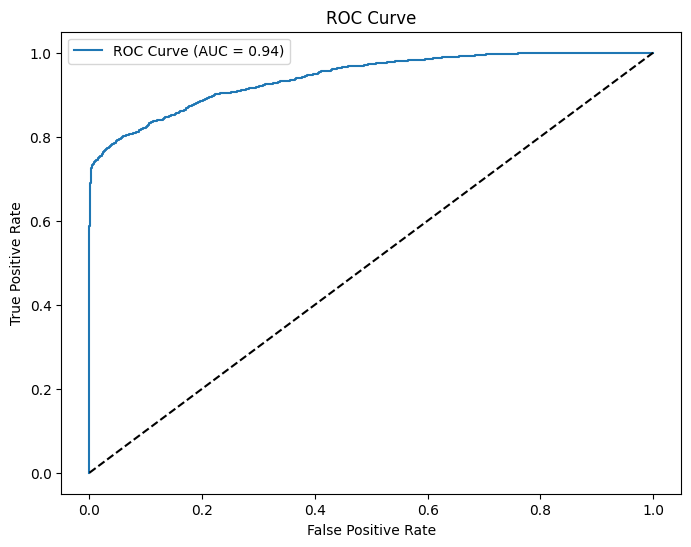


Model saved as 'credit_risk_model.pkl'


In [ ]:
# Credit Risk Prediction Model with Robust Dependency Handling

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                           f1_score, roc_auc_score, confusion_matrix,
                           classification_report, roc_curve, precision_recall_curve)
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                            VotingClassifier)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import joblib

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Optional imports with fallback
try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    print("XGBoost not available - will proceed without it")

try:
    from lightgbm import LGBMClassifier
    LGBM_AVAILABLE = True
except ImportError:
    LGBM_AVAILABLE = False
    print("LightGBM not available - will proceed without it")

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost not available - will proceed without it")

try:
    import optuna
    OPTUNA_AVAILABLE = True
except ImportError:
    OPTUNA_AVAILABLE = False
    print("Optuna not available - will use default hyperparameters")

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as imbpipeline
    IMBALANCE_AVAILABLE = True
except ImportError:
    IMBALANCE_AVAILABLE = False
    print("Imbalanced-learn not available - will proceed without SMOTE")

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not available - model explanations will be limited")

def load_data(filepath):
    """Load data with comprehensive error handling"""
    try:
        data = pd.read_csv(filepath)
        print(f"Data loaded successfully with shape: {data.shape}")
        return data
    except FileNotFoundError:
        raise FileNotFoundError(f"Error: File not found at {filepath}")
    except Exception as e:
        raise Exception(f"Error loading data: {str(e)}")

def clean_and_engineer_features(df):
    """Perform data cleaning and feature engineering"""
    if df.empty:
        return df

    df = df.copy()

    # Handle missing values
    df = df.dropna()

    # Remove unrealistic values
    df = df[(df['person_age'] >= 18) & (df['person_age'] <= 80)]
    df = df[(df['person_income'] >= 5000) & (df['person_income'] <= 1e7)]
    df = df[(df['person_emp_length'] >= 0) & (df['person_emp_length'] <= 50)]

    # Create informative features
    epsilon = 1e-6
    df['debt_to_income'] = df['loan_amnt'] / (df['person_income'] + epsilon)
    df['income_to_loan_ratio'] = df['person_income'] / (df['loan_amnt'] + epsilon)
    df['loan_to_credit_history_ratio'] = df['loan_amnt'] / (df['cb_person_cred_hist_length'] + epsilon)

    # Create binned features
    df['age_group'] = pd.cut(df['person_age'],
                            bins=[18, 25, 35, 45, 55, 65, 80],
                            labels=['18-24', '25-34', '35-44', '45-54', '55-64', '65+'])

    df['income_category'] = pd.cut(df['person_income'],
                                 bins=[0, 30000, 60000, 100000, float('inf')],
                                 labels=['low', 'medium', 'high', 'very high'])

    return df

def create_models():
    """Create models with available packages"""
    models = []

    # Always include Random Forest
    models.append(('rf', RandomForestClassifier(
        n_estimators=200, max_depth=15, random_state=RANDOM_STATE,
        class_weight='balanced', n_jobs=-1)))

    # Add other models if available
    if XGB_AVAILABLE:
        models.append(('xgb', XGBClassifier(
            n_estimators=200, max_depth=5, learning_rate=0.1,
            random_state=RANDOM_STATE, eval_metric='auc', use_label_encoder=False)))

    if LGBM_AVAILABLE:
        models.append(('lgbm', LGBMClassifier(
            n_estimators=200, max_depth=7, learning_rate=0.05,
            random_state=RANDOM_STATE, class_weight='balanced')))

    if CATBOOST_AVAILABLE:
        models.append(('cat', CatBoostClassifier(
            iterations=200, depth=6, learning_rate=0.05,
            random_state=RANDOM_STATE, verbose=0)))

    return models

def build_pipeline(models):
    """Build modeling pipeline"""
    # Define feature types
    num_features = ['person_age', 'person_income', 'person_emp_length',
                   'loan_amnt', 'loan_int_rate', 'loan_percent_income',
                   'cb_person_cred_hist_length', 'debt_to_income',
                   'income_to_loan_ratio', 'loan_to_credit_history_ratio']

    cat_features = ['person_home_ownership', 'loan_intent', 'loan_grade',
                   'cb_person_default_on_file', 'age_group', 'income_category']

    # Create preprocessing
    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())])

    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'))])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, num_features),
            ('cat', categorical_transformer, cat_features)])

    # Build pipeline
    if IMBALANCE_AVAILABLE:
        pipeline = imbpipeline([
            ('preprocessor', preprocessor),
            ('smote', SMOTE(random_state=RANDOM_STATE)),
            ('ensemble', VotingClassifier(estimators=models, voting='soft', n_jobs=-1))
        ])
    else:
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('ensemble', VotingClassifier(estimators=models, voting='soft', n_jobs=-1))
        ])

    return pipeline

def evaluate_model(model, X_test, y_test):
    """Evaluate model performance"""
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    if y_proba is not None:
        print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

        # Plot ROC curve
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        plt.figure(figsize=(8, 6))
        plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_proba):.2f})')
        plt.plot([0, 1], [0, 1], 'k--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curve')
        plt.legend()
        plt.show()

def main():
    """Main execution function"""
    try:
        # Load and prepare data
        data = load_data("/credit_risk_dataset.csv")
        data_cleaned = clean_and_engineer_features(data)

        if data_cleaned.empty:
            print("No data available after cleaning")
            return

        # Split data
        X = data_cleaned.drop(columns=['loan_status'])
        y = data_cleaned['loan_status']
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

        # Create and train model
        models = create_models()
        pipeline = build_pipeline(models)
        print("\nTraining model...")
        pipeline.fit(X_train, y_train)

        # Evaluate
        print("\nModel Evaluation:")
        evaluate_model(pipeline, X_test, y_test)

        # Save model
        joblib.dump(pipeline, 'credit_risk_model.pkl')
        print("\nModel saved as 'credit_risk_model.pkl'")

    except Exception as e:
        print(f"\nError in main execution: {str(e)}")

if __name__ == "__main__":
    main()

Environment setup complete

Loading dataset...
Successfully loaded 32581 records with 12 features

First 5 records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.000,PERSONAL,D,35000,16.020,1,0.590,Y,3
1,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0,0.100,N,2
2,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,1,0.570,N,3
3,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,1,0.530,N,2
4,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,1,0.550,Y,4



Data types:


,Data Type
person_age,int64
person_income,int64
person_home_ownership,object
person_emp_length,float64
loan_intent,object
loan_grade,object
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64



=== Basic Statistics ===


,count,mean,std,min,25%,50%,75%,max
person_age,32581.00,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.00,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.00,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.00,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.00,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32581.00,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.00,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.00,5.80,4.06,2.00,3.00,4.00,8.00,30.00



=== Missing Values Analysis ===


,Missing Values,% Missing
person_age,0,0.00%
person_income,0,0.00%
person_home_ownership,0,0.00%
person_emp_length,895,2.75%
loan_intent,0,0.00%
loan_grade,0,0.00%
loan_amnt,0,0.00%
loan_int_rate,3116,9.56%
loan_status,0,0.00%
loan_percent_income,0,0.00%



=== Target Variable Distribution ===


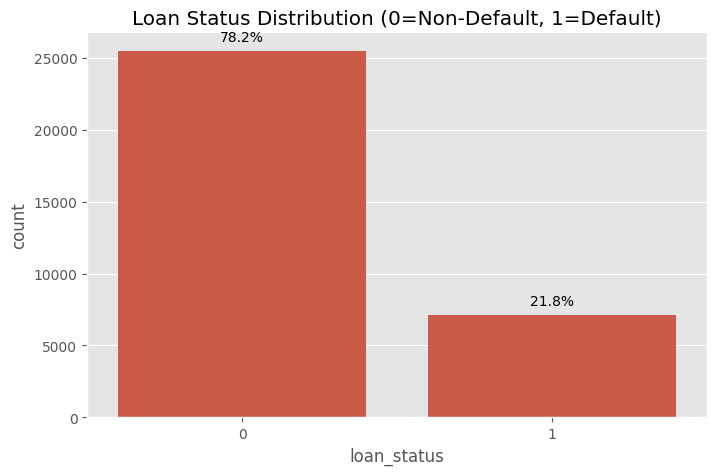


=== Numerical Features Distribution ===


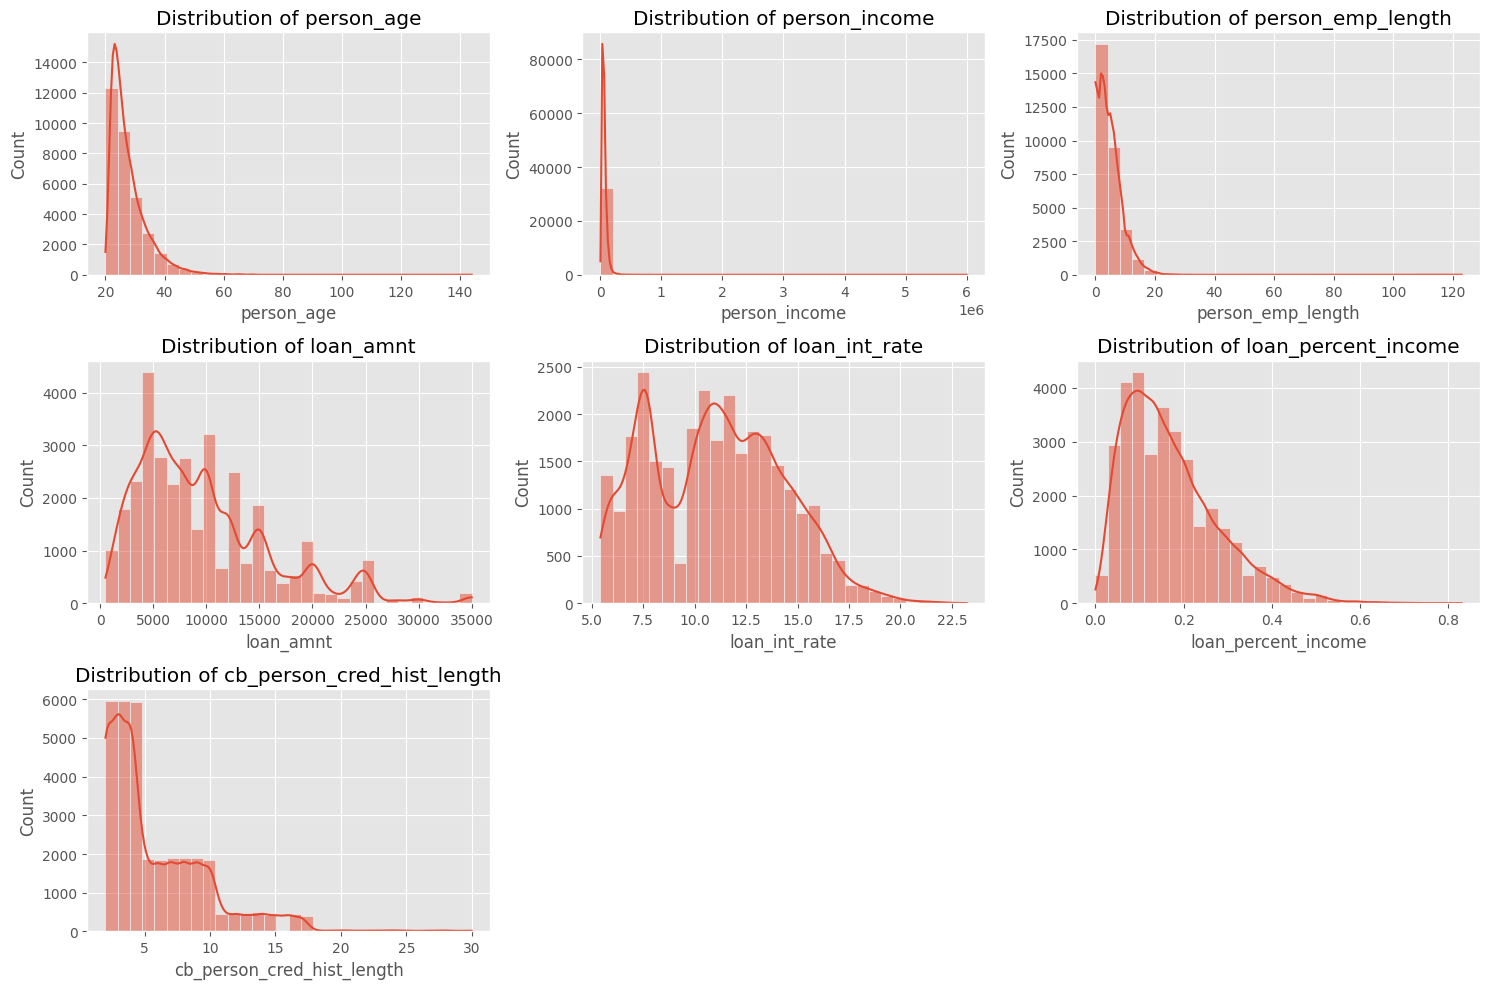


=== Categorical Features Analysis ===


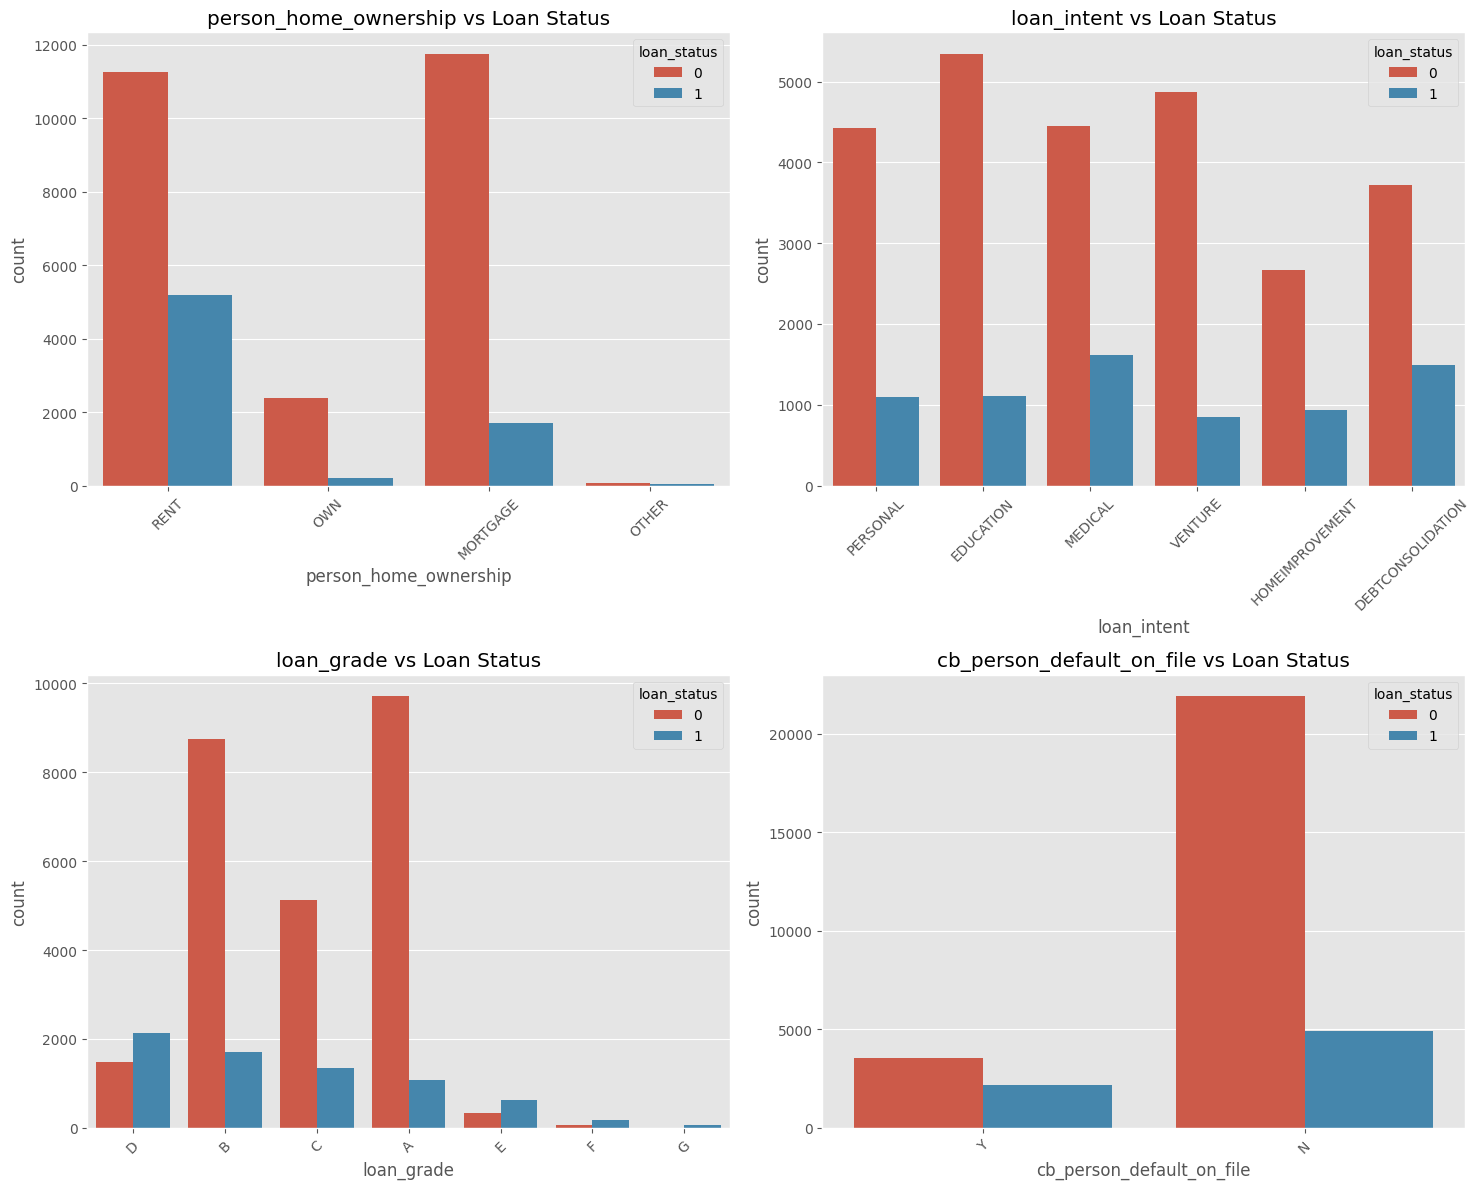


=== Correlation Analysis ===


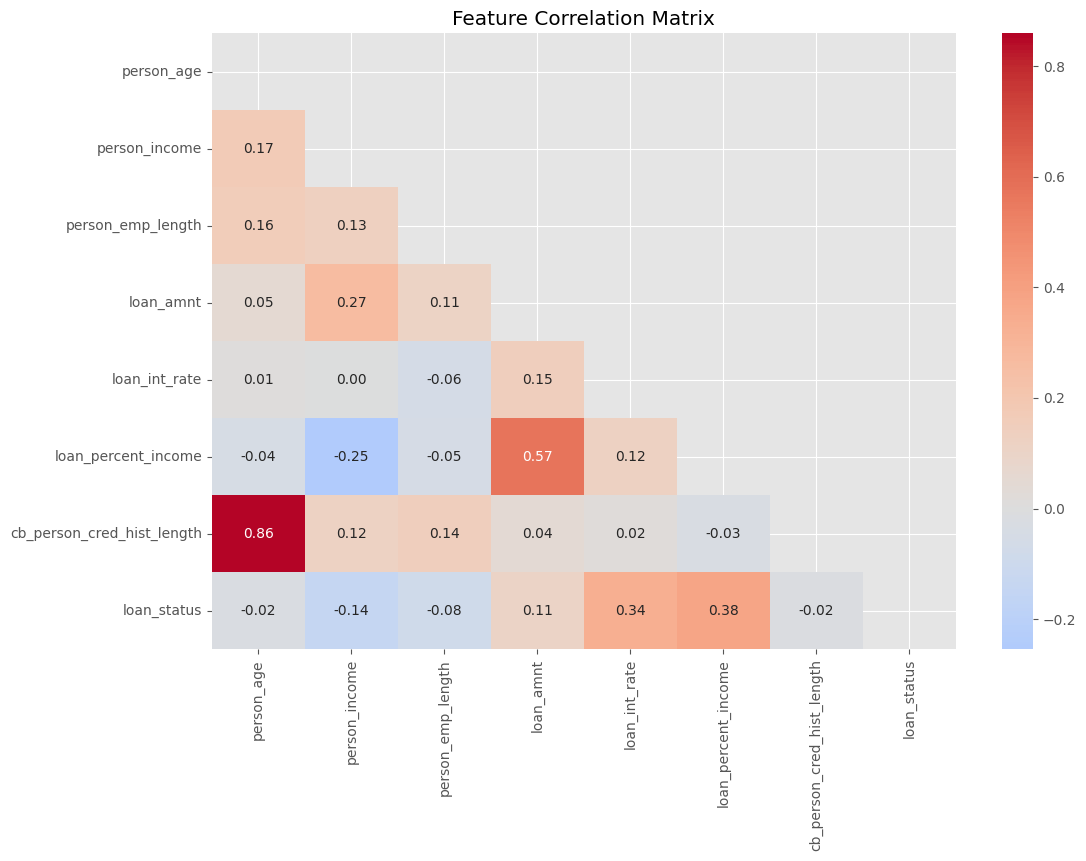


=== Data Cleaning ===

Handling missing values...
Records after dropping NA: 29465

Removing outliers...
Records after outlier removal: 28625

=== Feature Engineering ===

New features summary:


,debt_to_income,income_to_loan_ratio,age_group,income_category
count,28625.000,28625.000,28625,28625
unique,NaN,NaN,6,5
top,NaN,NaN,18-24,Low
freq,NaN,NaN,13479,12526
mean,0.170,9.668,NaN,NaN
std,0.107,11.126,NaN,NaN
min,0.001,1.205,NaN,NaN
25%,0.089,4.387,NaN,NaN
50%,0.147,6.800,NaN,NaN
75%,0.228,11.200,NaN,NaN



=== Preparing Data for Modeling ===

=== Training Random Forest Model ===
Model training completed

=== Model Performance Metrics ===

Detailed Classification Report:
              precision    recall  f1-score   support

           0      0.933     0.987     0.959      4485
           1      0.941     0.742     0.830      1240

    accuracy                          0.934      5725
   macro avg      0.937     0.865     0.894      5725
weighted avg      0.934     0.934     0.931      5725


Confusion Matrix:


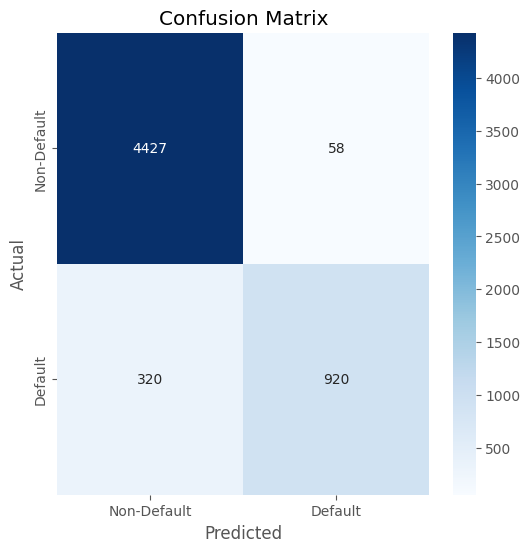


=== Probability Distributions ===


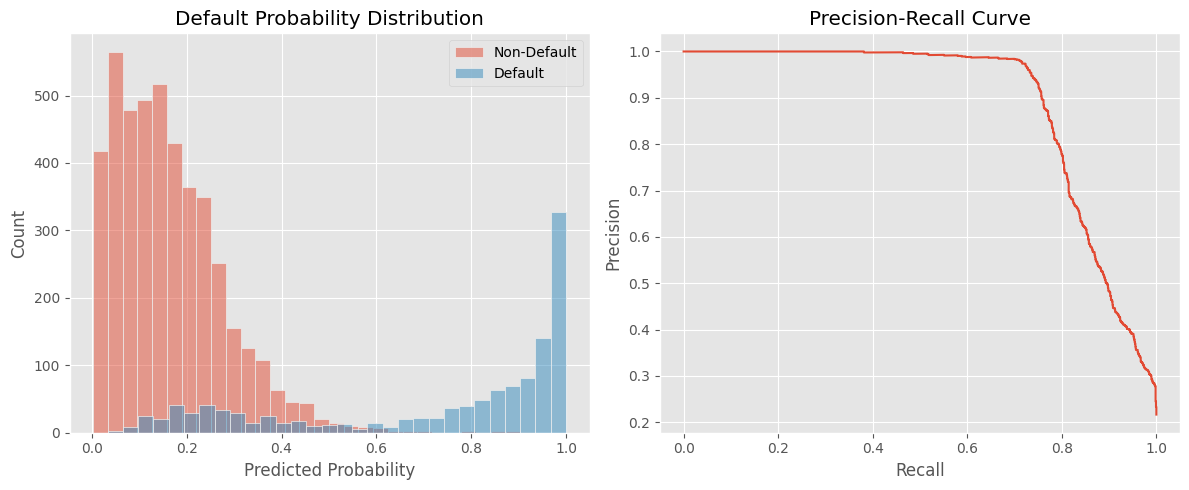


=== ROC Curve ===


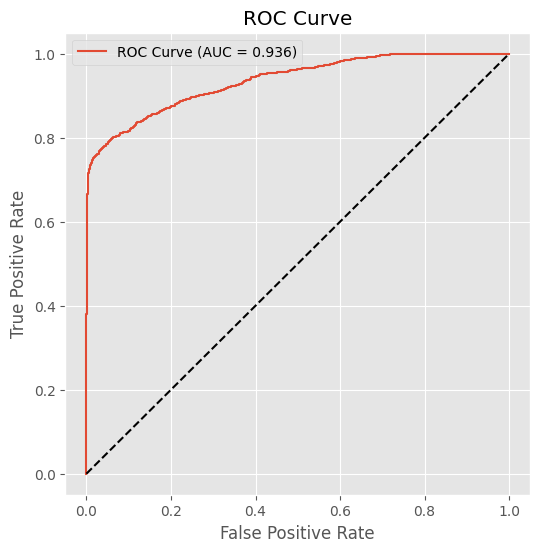


=== Feature Importance ===


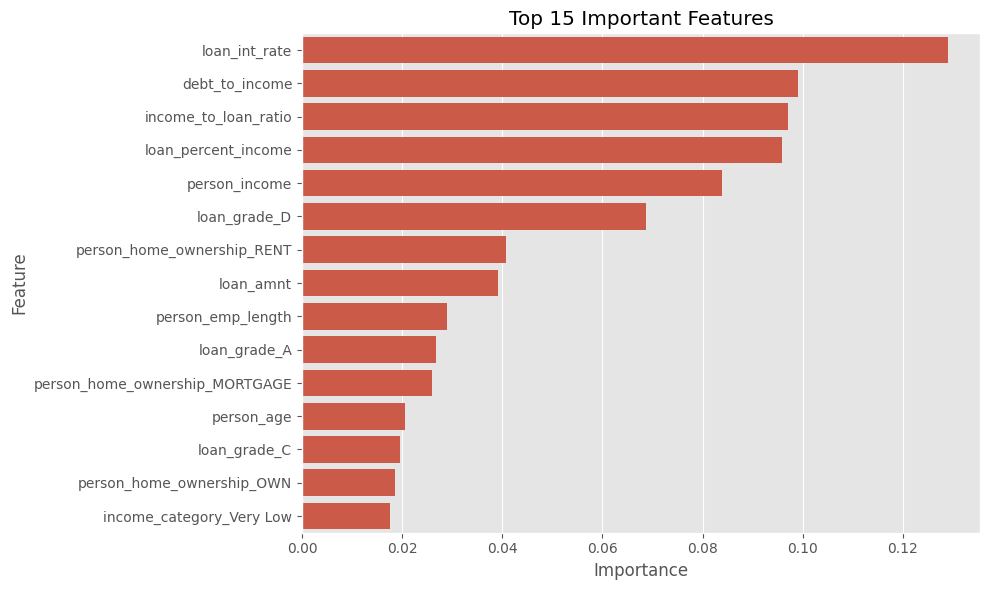

,Feature,Importance
4,loan_int_rate,0.1289
7,debt_to_income,0.0991
8,income_to_loan_ratio,0.0971
5,loan_percent_income,0.0959
1,person_income,0.0838
22,loan_grade_D,0.0687
12,person_home_ownership_RENT,0.0407
3,loan_amnt,0.0392
2,person_emp_length,0.0290
19,loan_grade_A,0.0267



=== Risk Profile Analysis ===


/tmp/ipython-input-20-2203947522.py:266: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



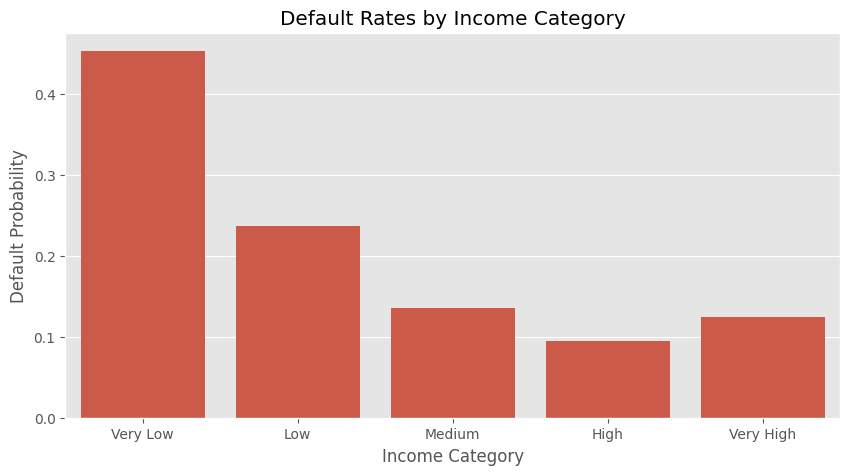


Default Rates by Income Category:


,Income Category,Default Rate,Count
0,Very Low,0.453,3750
1,Low,0.237,12526
2,Medium,0.135,8622
4,Very High,0.125,401
3,High,0.095,3326



=== Loan Grade Risk Analysis ===


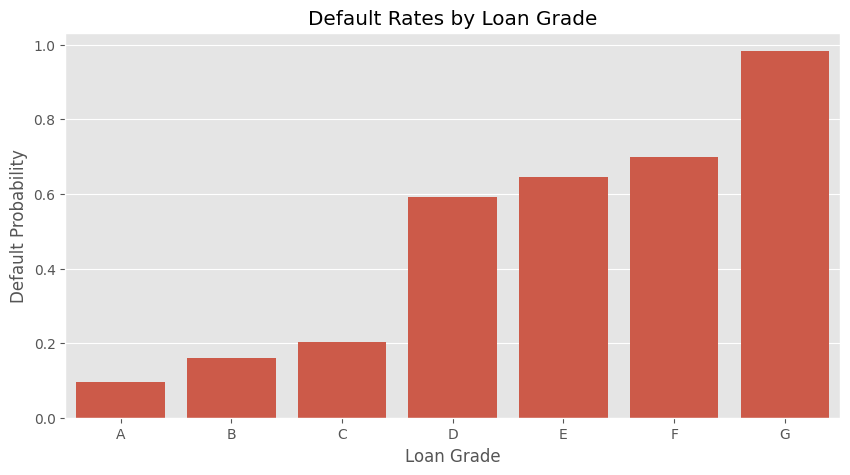


Default Rates by Loan Grade:


,Loan Grade,Default Rate,Count
6,G,0.983,59
5,F,0.699,209
4,E,0.646,870
3,D,0.592,3247
2,C,0.203,5695
1,B,0.159,9149
0,A,0.096,9396


/tmp/ipython-input-20-2203947522.py:300: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



/tmp/ipython-input-20-2203947522.py:312: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [ ]:
# %% [markdown]
# ## 1. Environment Setup & Data Loading

# %%
# Core packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                           roc_auc_score, precision_recall_curve, roc_curve)
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Visualization settings
plt.style.use('ggplot')
%matplotlib inline
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.max_columns', 100)
print("Environment setup complete")

# %%
# Load and verify data
print("\nLoading dataset...")
try:
    data = pd.read_csv('/credit_risk_dataset.csv')
    print(f"Successfully loaded {len(data)} records with {len(data.columns)} features")

    print("\nFirst 5 records:")
    display(data.head())

    print("\nData types:")
    display(data.dtypes.to_frame('Data Type'))

except Exception as e:
    print(f"Error loading data: {str(e)}")
    raise

# %% [markdown]
# ## 2. Comprehensive Data Exploration

# %%
print("\n=== Basic Statistics ===")
display(data.describe().T.style.format("{:.2f}"))

print("\n=== Missing Values Analysis ===")
missing = data.isnull().sum().to_frame('Missing Values')
missing['% Missing'] = (missing['Missing Values']/len(data)*100).round(2)
display(missing.style.format({'% Missing': '{:.2f}%'}))

# %%
print("\n=== Target Variable Distribution ===")
plt.figure(figsize=(8,5))
ax = sns.countplot(x='loan_status', data=data)
total = len(data)
for p in ax.patches:
    percentage = f'{100 * p.get_height()/total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='center', xytext=(0,10), textcoords='offset points')
plt.title('Loan Status Distribution (0=Non-Default, 1=Default)')
plt.show()

# %%
print("\n=== Numerical Features Distribution ===")
num_cols = ['person_age', 'person_income', 'person_emp_length',
            'loan_amnt', 'loan_int_rate', 'loan_percent_income',
            'cb_person_cred_hist_length']

plt.figure(figsize=(15,10))
for i, col in enumerate(num_cols):
    plt.subplot(3,3,i+1)
    sns.histplot(data[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# %%
print("\n=== Categorical Features Analysis ===")
cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade',
            'cb_person_default_on_file']

plt.figure(figsize=(15,12))
for i, col in enumerate(cat_cols):
    plt.subplot(2,2,i+1)
    sns.countplot(x=col, hue='loan_status', data=data)
    plt.title(f'{col} vs Loan Status')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# %%
print("\n=== Correlation Analysis ===")
plt.figure(figsize=(12,8))
corr = data[num_cols + ['loan_status']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

# %% [markdown]
# ## 3. Data Cleaning & Feature Engineering

# %%
print("\n=== Data Cleaning ===")
data_clean = data.copy()

# Handle missing values
print("\nHandling missing values...")
data_clean = data_clean.dropna(subset=['loan_int_rate'])  # Critical feature
print(f"Records after dropping NA: {len(data_clean)}")

# Remove unrealistic values
print("\nRemoving outliers...")
data_clean = data_clean[(data_clean['person_age'] >= 18) &
                        (data_clean['person_age'] <= 80)]
data_clean = data_clean[(data_clean['person_income'] >= 1000) &
                        (data_clean['person_income'] <= 1e6)]
data_clean = data_clean[(data_clean['person_emp_length'] >= 0) &
                        (data_clean['person_emp_length'] <= 50)]
print(f"Records after outlier removal: {len(data_clean)}")

# %%
print("\n=== Feature Engineering ===")
# Financial ratios
data_clean['debt_to_income'] = data_clean['loan_amnt'] / (data_clean['person_income'] + 1e-6)
data_clean['income_to_loan_ratio'] = data_clean['person_income'] / (data_clean['loan_amnt'] + 1e-6)

# Binning continuous variables
data_clean['age_group'] = pd.cut(data_clean['person_age'],
                               bins=[18,25,35,45,55,65,80],
                               labels=['18-24','25-34','35-44','45-54','55-64','65+'])

data_clean['income_category'] = pd.cut(data_clean['person_income'],
                                    bins=[0,30000,60000,100000,200000,float('inf')],
                                    labels=['Very Low','Low','Medium','High','Very High'])

# Interaction features
data_clean['loan_intent_income'] = data_clean['loan_intent'] + "_" + data_clean['income_category'].astype(str)

print("\nNew features summary:")
display(data_clean[['debt_to_income','income_to_loan_ratio','age_group','income_category']].describe(include='all'))

# %% [markdown]
# ## 4. Model Development

# %%
print("\n=== Preparing Data for Modeling ===")
X = data_clean.drop('loan_status', axis=1)
y = data_clean['loan_status']

# Define feature types
num_features = ['person_age', 'person_income', 'person_emp_length',
               'loan_amnt', 'loan_int_rate', 'loan_percent_income',
               'cb_person_cred_hist_length', 'debt_to_income',
               'income_to_loan_ratio']

cat_features = ['person_home_ownership', 'loan_intent', 'loan_grade',
               'cb_person_default_on_file', 'age_group', 'income_category',
               'loan_intent_income']

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ])

# %%
print("\n=== Training Random Forest Model ===")
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

model.fit(X_train, y_train)
print("Model training completed")

# %% [markdown]
# ## 5. Model Evaluation

# %%
print("\n=== Model Performance Metrics ===")
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:,1]

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, digits=3))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Non-Default', 'Default'],
           yticklabels=['Non-Default', 'Default'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# %%
print("\n=== Probability Distributions ===")
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.histplot(y_proba[y_test==0], bins=30, alpha=0.5, label='Non-Default')
sns.histplot(y_proba[y_test==1], bins=30, alpha=0.5, label='Default')
plt.xlabel('Predicted Probability')
plt.title('Default Probability Distribution')
plt.legend()

plt.subplot(1,2,2)
precision, recall, _ = precision_recall_curve(y_test, y_proba)
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.tight_layout()
plt.show()

# %%
print("\n=== ROC Curve ===")
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_proba):.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# %%
print("\n=== Feature Importance ===")
feature_names = (num_features +
                list(model.named_steps['preprocessor']
                    .named_transformers_['cat']
                    .get_feature_names_out(cat_features)))

importances = model.named_steps['classifier'].feature_importances_
feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp = feat_imp.sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=feat_imp)
plt.title('Top 15 Important Features')
plt.tight_layout()
plt.show()

display(feat_imp.style.format({'Importance': '{:.4f}'}))

# %% [markdown]
# ## 6. Business Insights

# %%
print("\n=== Risk Profile Analysis ===")
risk_profiles = data_clean.groupby('income_category')['loan_status'].agg(
    ['mean', 'count']).reset_index()
risk_profiles.columns = ['Income Category', 'Default Rate', 'Count']
risk_profiles['Default Rate'] = risk_profiles['Default Rate'].round(3)

plt.figure(figsize=(10,5))
sns.barplot(x='Income Category', y='Default Rate', data=risk_profiles)
plt.title('Default Rates by Income Category')
plt.ylabel('Default Probability')
plt.show()

print("\nDefault Rates by Income Category:")
display(risk_profiles.sort_values('Default Rate', ascending=False))

# %%
print("\n=== Loan Grade Risk Analysis ===")
grade_risk = data_clean.groupby('loan_grade')['loan_status'].agg(
    ['mean', 'count']).reset_index()
grade_risk.columns = ['Loan Grade', 'Default Rate', 'Count']
grade_risk['Default Rate'] = grade_risk['Default Rate'].round(3)

plt.figure(figsize=(10,5))
sns.barplot(x='Loan Grade', y='Default Rate', data=grade_risk)
plt.title('Default Rates by Loan Grade')
plt.ylabel('Default Probability')
plt.show()

print("\nDefault Rates by Loan Grade:")
display(grade_risk.sort_values('Default Rate', ascending=False))

# %% [markdown]
# ## 5. Business Insights Visualization (Updated with Age Group Analysis)
# %%
# 1. Default Rates by Income Category
risk_profiles = data_clean.groupby('income_category')['loan_status'].agg(
    ['mean', 'count']).reset_index()
risk_profiles.columns = ['Income Category', 'Default Rate', 'Count']

fig = px.bar(risk_profiles, x='Income Category', y='Default Rate',
             color='Count', color_continuous_scale='Viridis',
             labels={'Default Rate':'Default Probability'},
             title='Default Risk by Income Category (Darker = More Samples)')
fig.update_layout(yaxis_tickformat=".1%")
fig.show()

# 2. Default Rates by Age Group (NEW ADDITION)
age_risk = data_clean.groupby('age_group')['loan_status'].agg(
    ['mean', 'count']).reset_index()
age_risk.columns = ['Age Group', 'Default Rate', 'Count']

fig = px.bar(age_risk, x='Age Group', y='Default Rate',
             color='Count', color_continuous_scale='Bluered',
             labels={'Default Rate':'Default Probability'},
             title='Default Risk by Age Group (Darker = More Samples)',
             category_orders={"Age Group": ['18-24','25-34','35-44','45-54','55-64','65+']})
fig.update_layout(yaxis_tickformat=".1%")
fig.show()

# 3. Default Rates by Loan Grade
grade_risk = data_clean.groupby('loan_grade')['loan_status'].agg(
    ['mean', 'count']).reset_index()
grade_risk.columns = ['Loan Grade', 'Default Rate', 'Count']

fig = px.bar(grade_risk, x='Loan Grade', y='Default Rate',
             color='Count', color_continuous_scale='RdBu_r',
             labels={'Default Rate':'Default Probability'},
             title='Default Risk by Loan Grade (Darker = More Samples)')
fig.update_layout(yaxis_tickformat=".1%")
fig.show()

# 4. Feature Importance
feature_names = (num_features +
                list(model.named_steps['preprocessor']
                    .named_transformers_['cat']
                    .get_feature_names_out(cat_features)))

importances = model.named_steps['classifier'].feature_importances_
feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp['Category'] = feat_imp['Feature'].apply(
    lambda x: 'Numerical' if x in num_features else 'Categorical')

fig = px.treemap(feat_imp.nlargest(20, 'Importance'),
                path=['Category', 'Feature'],
                values='Importance',
                color='Importance',
                color_continuous_scale='RdBu',
                title='Top 20 Feature Importance')
fig.show()